In [1]:
import pandas as pd, numpy as np
df = pd.read_csv("../data/raw/Tuesday-WorkingHours.pcap_ISCX.csv")
df.columns = df.columns.str.strip()      # fixes the leading-space problem
print(df.shape)
print(df["Label"].value_counts())

(445909, 79)
Label
BENIGN         432074
FTP-Patator      7938
SSH-Patator      5897
Name: count, dtype: int64


In [2]:
df = df.drop(columns=["Fwd Header Length.1"], errors="ignore")   # the duplicated column
df = df.replace([np.inf, -np.inf], np.nan)
print("NaN cells:", df.isna().sum().sum())
df = df.dropna()
before = len(df)
df = df.drop_duplicates()
print("duplicates removed:", before - len(df))
nun = df.nunique()
df = df.drop(columns=nun[nun <= 1].index)     # columns with a single value carry no information

NaN cells: 528
duplicates removed: 24019


In [3]:
from sklearn.model_selection import train_test_split
y = (df["Label"] != "BENIGN").astype(int)
X = df.drop(columns="Label")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix

def evaluate(model, name, Xte=None):
    Xte = X_test if Xte is None else Xte
    proba = model.predict_proba(Xte)[:, 1]
    pred = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{name}: PR-AUC={average_precision_score(y_test, proba):.4f} "
          f"recall={tp/(tp+fn):.4f} precision={tp/max(tp+fp,1):.4f} FPR={fp/(fp+tn):.5f}")

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Dummy accuracy:", dummy.score(X_test, y_test))   # looks high, but it catches nothing
evaluate(dummy, "Dummy")

lr = Pipeline([("scale", StandardScaler()),
               ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))])
lr.fit(X_train, y_train)
evaluate(lr, "LogReg")

Dummy accuracy: 0.9782983366011005
Dummy: PR-AUC=0.0217 recall=0.0000 precision=0.0000 FPR=0.00000
LogReg: PR-AUC=0.9705 recall=0.9960 precision=0.6628 FPR=0.01124


In [8]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

rf = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                            n_jobs=-1, random_state=42).fit(X_train, y_train)
evaluate(rf, "RandomForest")

spw = (y_train == 0).sum() / (y_train == 1).sum()   # class-imbalance weight
xgb = XGBClassifier(n_estimators=200, max_depth=6, scale_pos_weight=spw,
                    n_jobs=-1, random_state=42).fit(X_train, y_train)
evaluate(xgb, "XGBoost")

RandomForest: PR-AUC=0.9996 recall=0.9978 precision=1.0000 FPR=0.00000
XGBoost: PR-AUC=0.9997 recall=0.9996 precision=1.0000 FPR=0.00000


In [6]:
from sklearn.metrics import confusion_matrix
pred = (xgb.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
print(confusion_matrix(y_test, pred))      # rows = actual, columns = predicted

imp = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp.head(10))

[[123743      0]
 [     1   2744]]
Destination Port           0.967206
min_seg_size_forward       0.013014
Total Fwd Packets          0.004278
Flow Packets/s             0.004243
Fwd Packet Length Mean     0.002882
Fwd Packet Length Std      0.002568
Flow Bytes/s               0.001257
Init_Win_bytes_backward    0.000729
Down/Up Ratio              0.000534
Fwd IAT Min                0.000466
dtype: float32


In [9]:
cols = [c for c in X_train.columns if c != "Destination Port"]   # every column except the port
xgb_np = XGBClassifier(n_estimators=200, max_depth=6, scale_pos_weight=spw,
                       n_jobs=-1, random_state=42).fit(X_train[cols], y_train)  # same settings, fewer features
evaluate(xgb_np, "XGB no port", X_test[cols])   # test with the same reduced columns

XGB no port: PR-AUC=0.9996 recall=0.9985 precision=0.9996 FPR=0.00001


In [10]:
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report

le = LabelEncoder()
y_multi = le.fit_transform(df["Label"])
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(
    X, y_multi, test_size=0.3, stratify=y_multi, random_state=42)

xgb_m = XGBClassifier(n_estimators=200, max_depth=6, n_jobs=-1, random_state=42)
xgb_m.fit(Xm_tr, ym_tr, sample_weight=compute_sample_weight("balanced", ym_tr))
print(classification_report(ym_te, xgb_m.predict(Xm_te), target_names=le.classes_))

              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00    123743
 FTP-Patator       1.00      1.00      1.00      1779
 SSH-Patator       1.00      1.00      1.00       966

    accuracy                           1.00    126488
   macro avg       1.00      1.00      1.00    126488
weighted avg       1.00      1.00      1.00    126488



In [12]:
cols = [c for c in X.columns if c != "Destination Port"]
Xm_tr2, Xm_te2 = Xm_tr[cols], Xm_te[cols]
xgb_m2 = XGBClassifier(n_estimators=200, max_depth=6, n_jobs=-1, random_state=42)
xgb_m2.fit(Xm_tr2, ym_tr, sample_weight=compute_sample_weight("balanced", ym_tr))
print(classification_report(ym_te, xgb_m2.predict(Xm_te2), target_names=le.classes_, digits=4))

              precision    recall  f1-score   support

      BENIGN     1.0000    1.0000    1.0000    123743
 FTP-Patator     0.9994    0.9994    0.9994      1779
 SSH-Patator     0.9990    1.0000    0.9995       966

    accuracy                         1.0000    126488
   macro avg     0.9995    0.9998    0.9996    126488
weighted avg     1.0000    1.0000    1.0000    126488



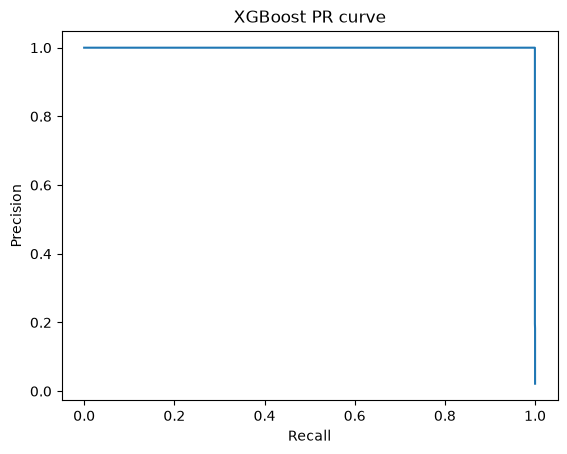

In [13]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt
p, r, t = precision_recall_curve(y_test, xgb.predict_proba(X_test)[:, 1])
plt.plot(r, p); plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("XGBoost PR curve")
plt.savefig("../docs/pr_curve_xgb.png", dpi=150, bbox_inches="tight")

In [14]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump(xgb, "../models/xgb_binary.joblib")
joblib.dump(list(X_train.columns), "../models/feature_columns.joblib")

['../models/feature_columns.joblib']